In [1]:
import numpy as np
import matplotlib.pyplot as plt
import polars as pl

from nucleo.io.reading import reading_all_parquet
plt.rcParams["font.size"] = 16

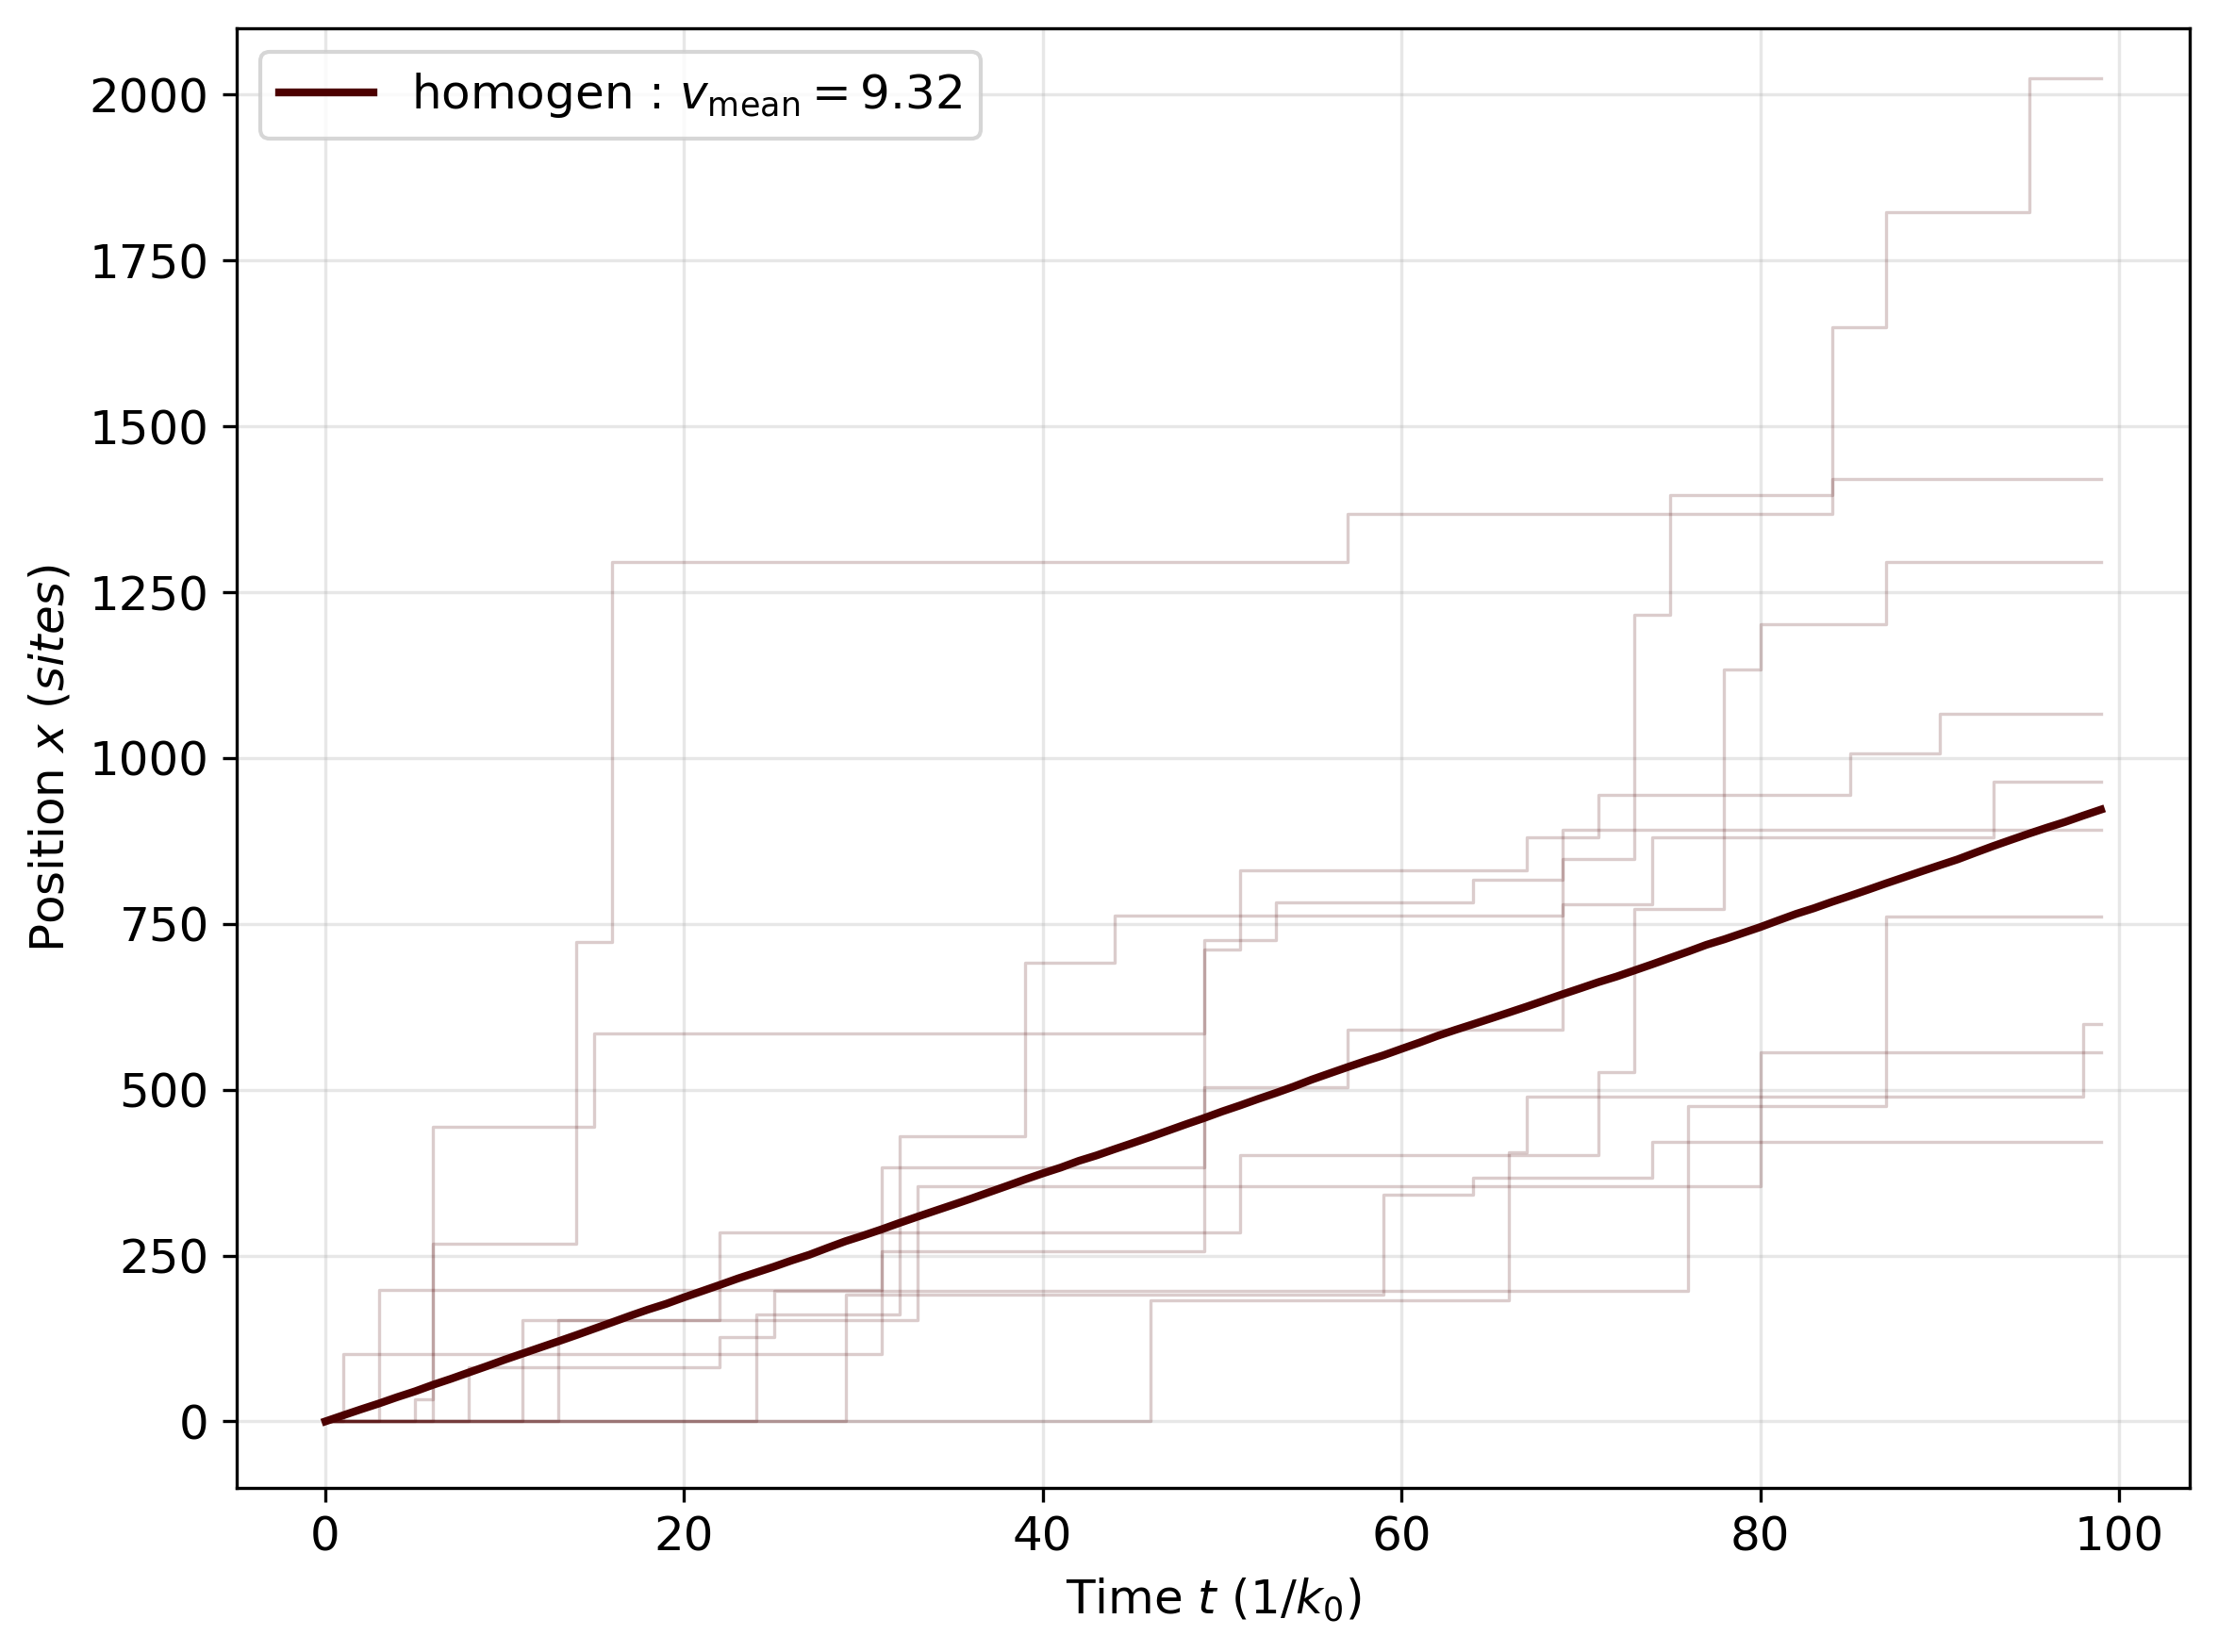

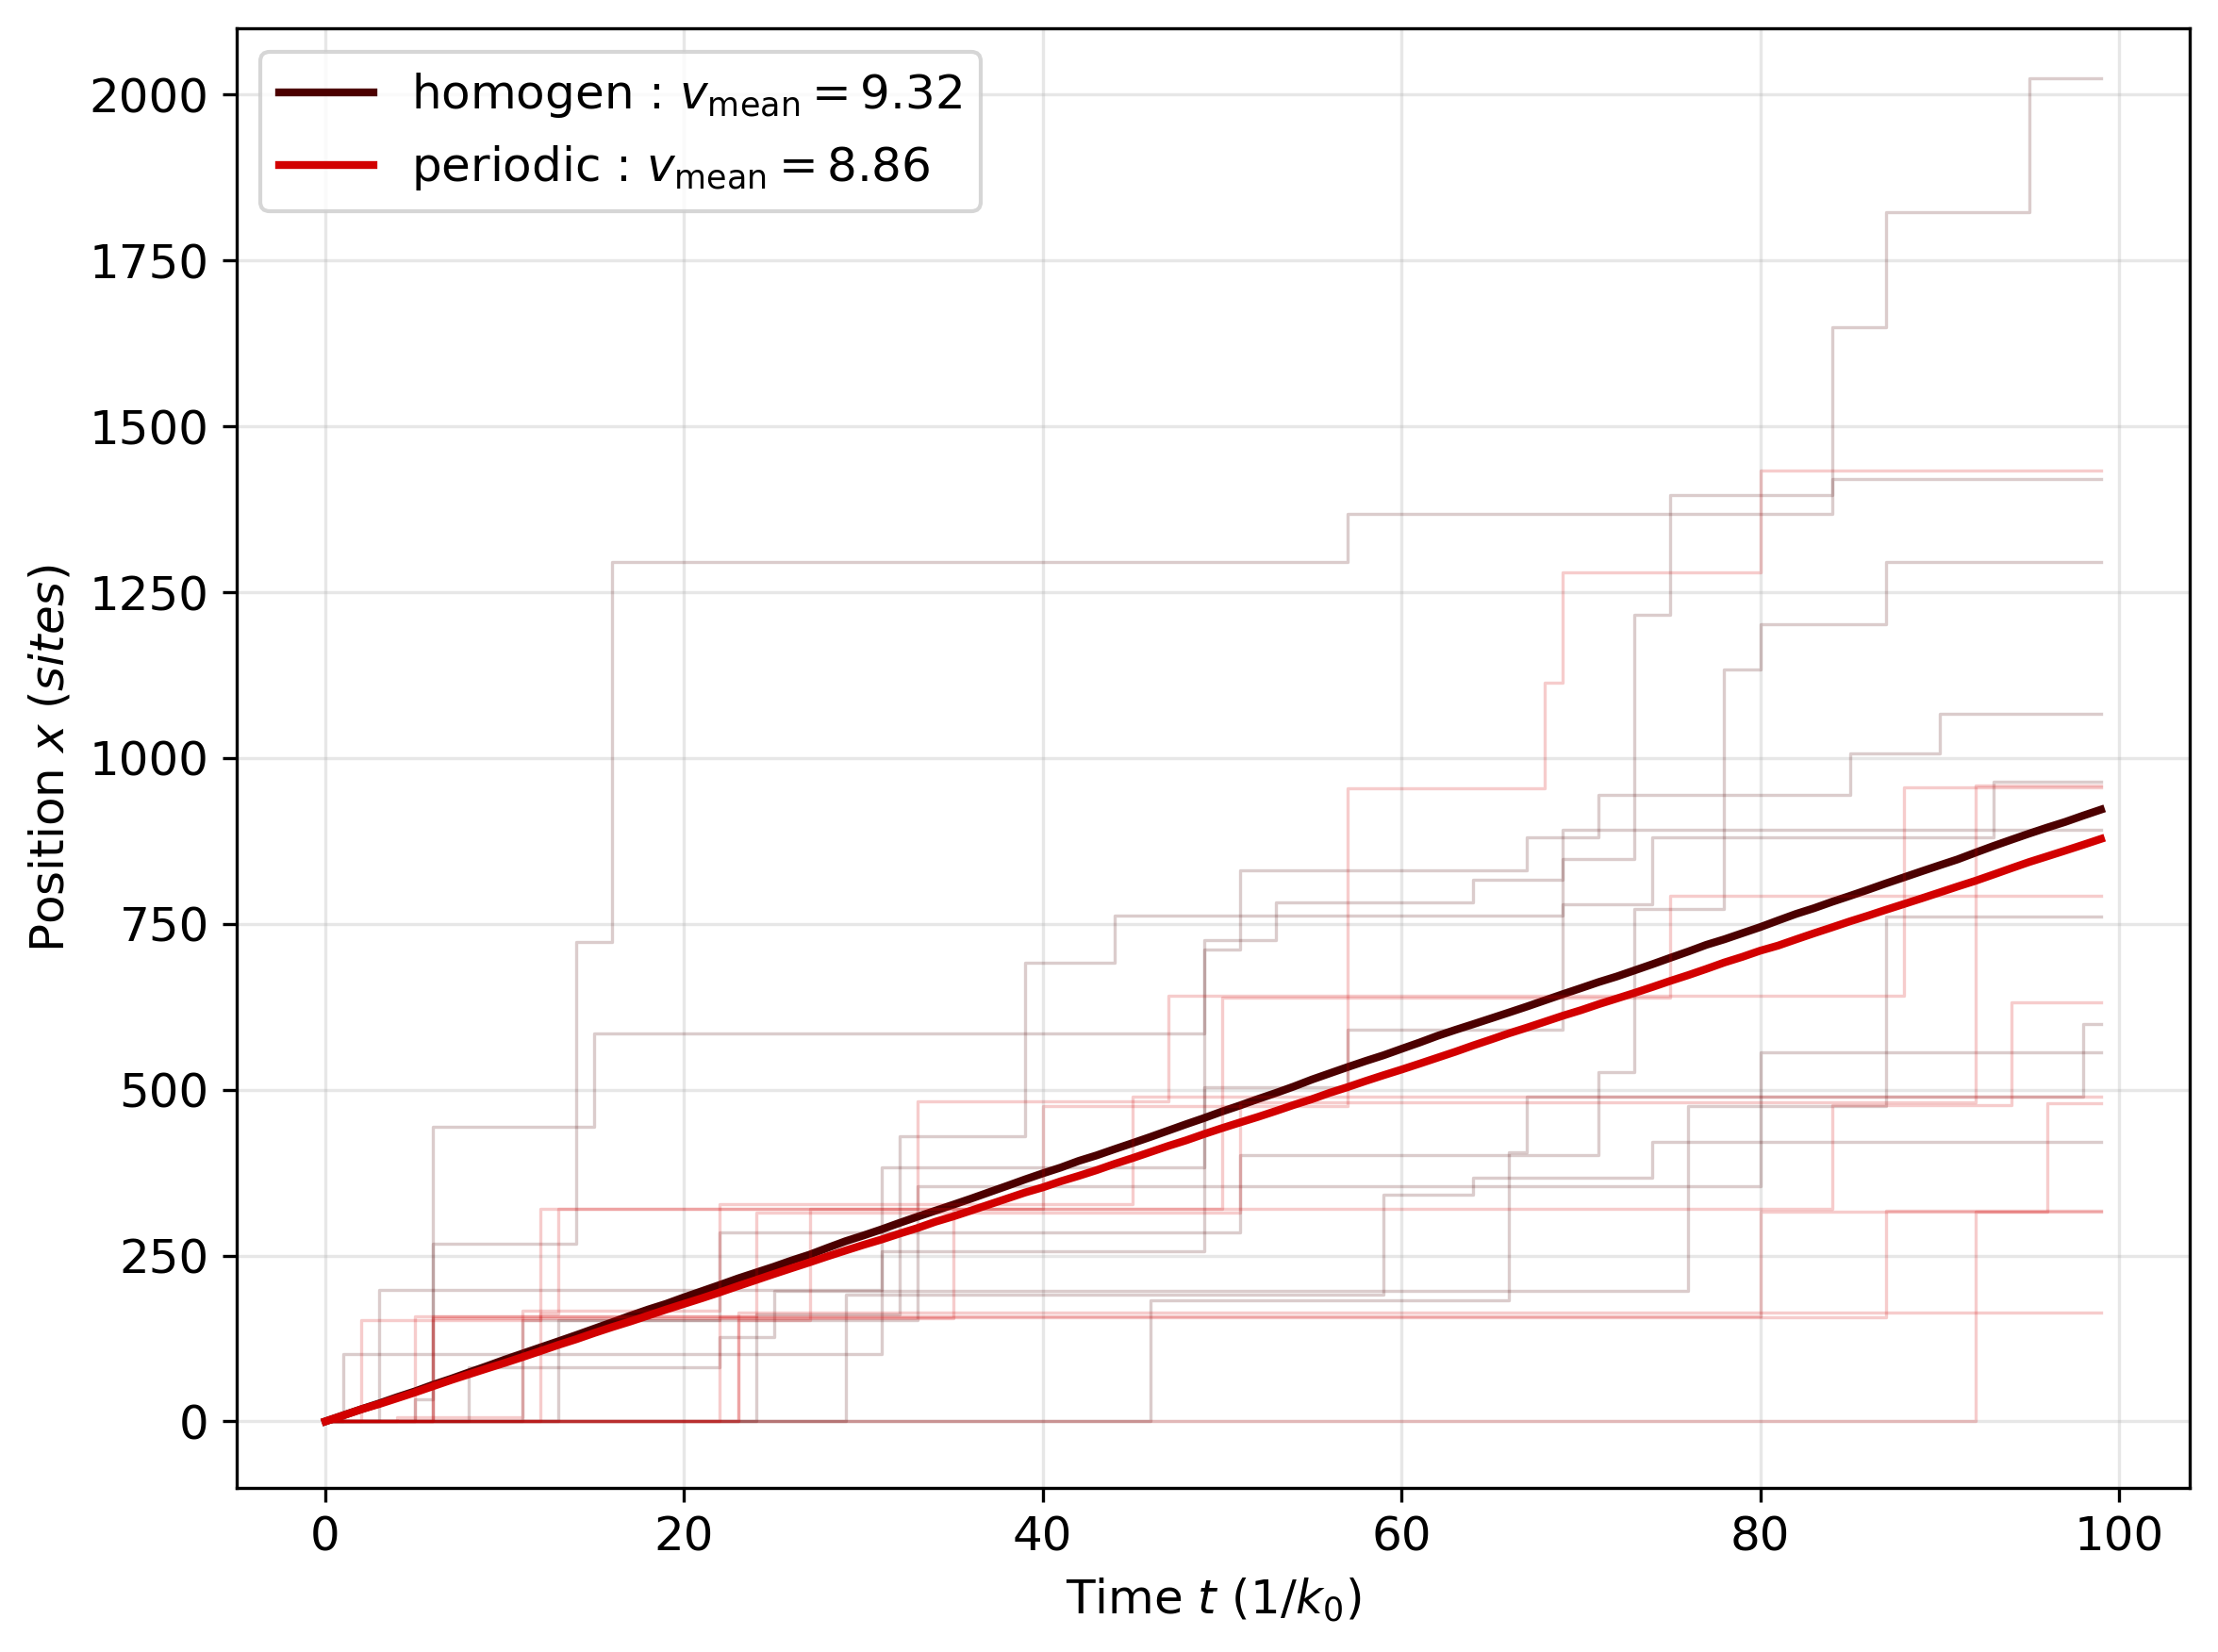

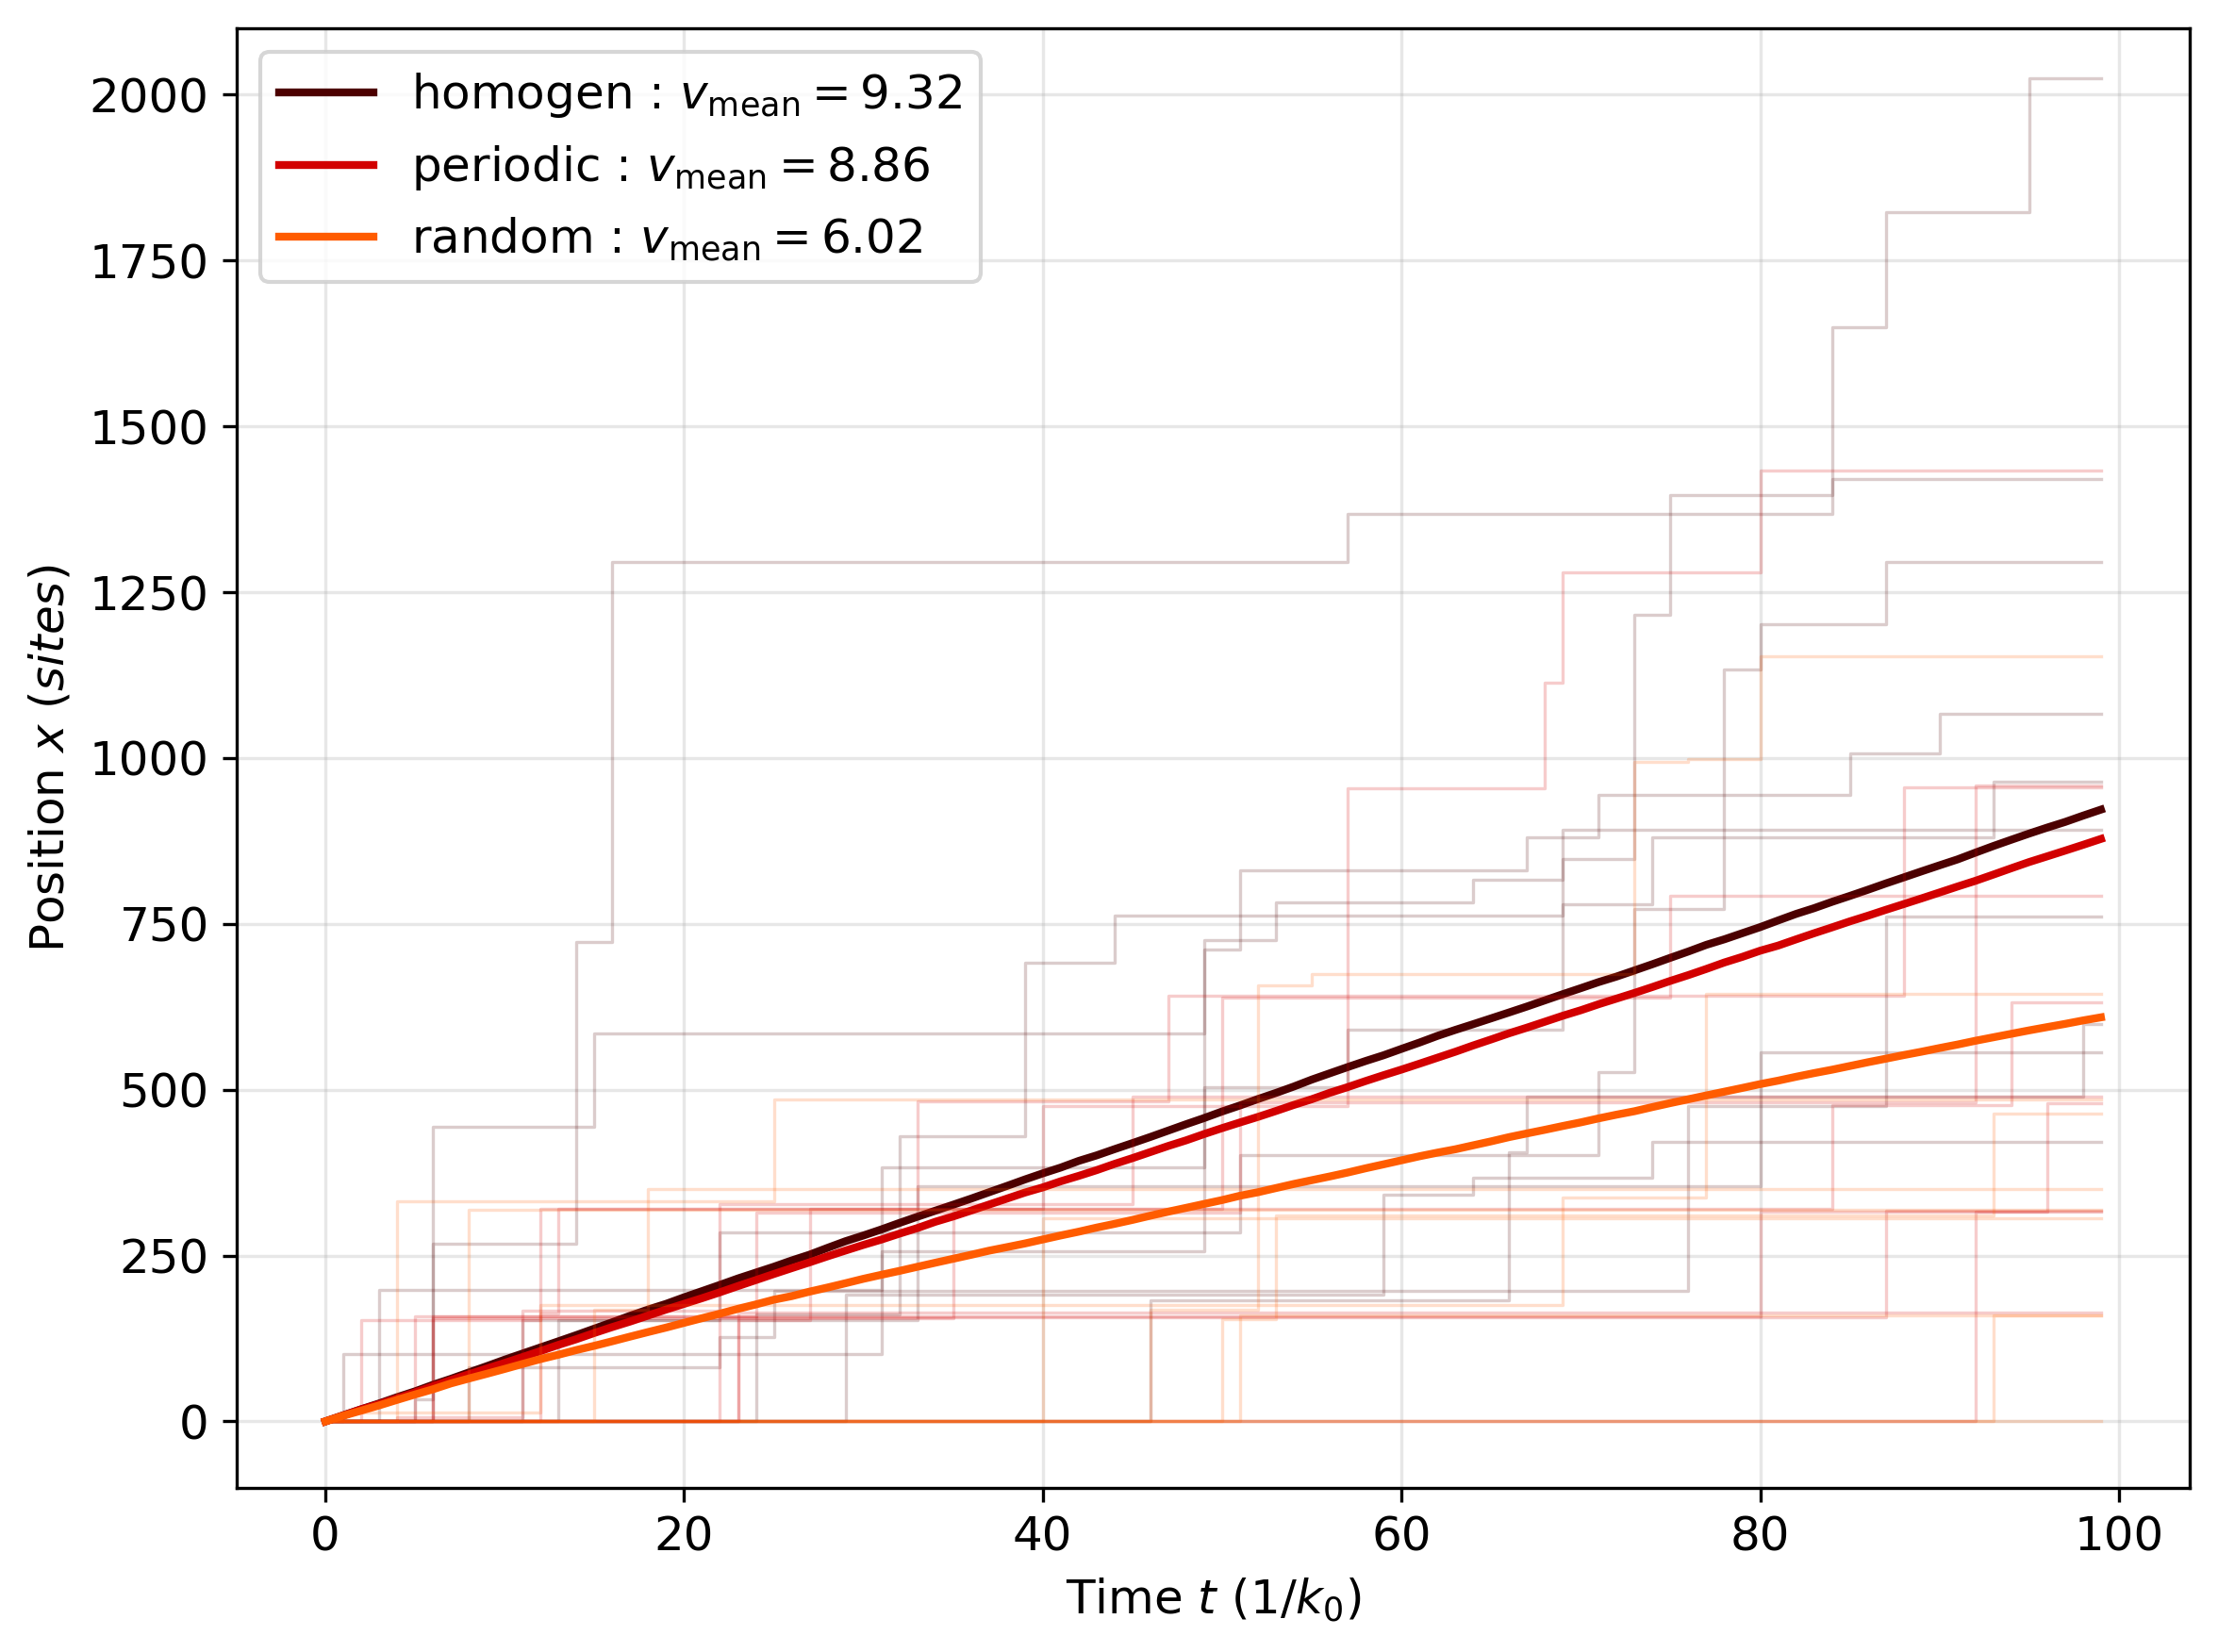

In [3]:
root = "/home/nicolas/Documents/Workspace/nucleo/outputs/FIGPRES__PC__2026-10-27/nucleo__figpres__0"
df = reading_all_parquet(root, extra_cols=["results_mean", "results"])

plt.rcParams["font.size"] = 12

cmap = plt.get_cmap("hot")
colors = cmap(np.linspace(0.10, 0.50, len(df)))

rows = list(df.iter_rows(named=True))

# Figures successives : homogène, périodique, aléatoire
for n in range(1, 4):

    plt.figure(figsize=(8, 6), dpi=300)

    for i, row in enumerate(rows[:n]):

        title = row["land"]
        results = row["results"]
        results_mean = row["results_mean"]
        v_mean = row["v_mean"]

        # 10 trajectoires stochastiques en arrière-plan
        for j in range(10):
            plt.plot(
                results[j],
                color=colors[i],
                alpha=0.20,
                linewidth=0.8,
                drawstyle="steps-post"
            )

        # Courbe moyenne au premier plan
        plt.plot(
            results_mean,
            color=colors[i],
            linewidth=2,
            label=rf"{title} : $v_{{\mathrm{{mean}}}} = {v_mean:.2f}$"
        )

    plt.xlabel(r"Time $t~(1/k_0)$")
    plt.ylabel(r"Position $x~(sites)$")
    plt.ylim(-100, 2100)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

Forward | mu = 37.20 | theta = 23.85
Reverse | mu = 36.77 | theta = 24.63


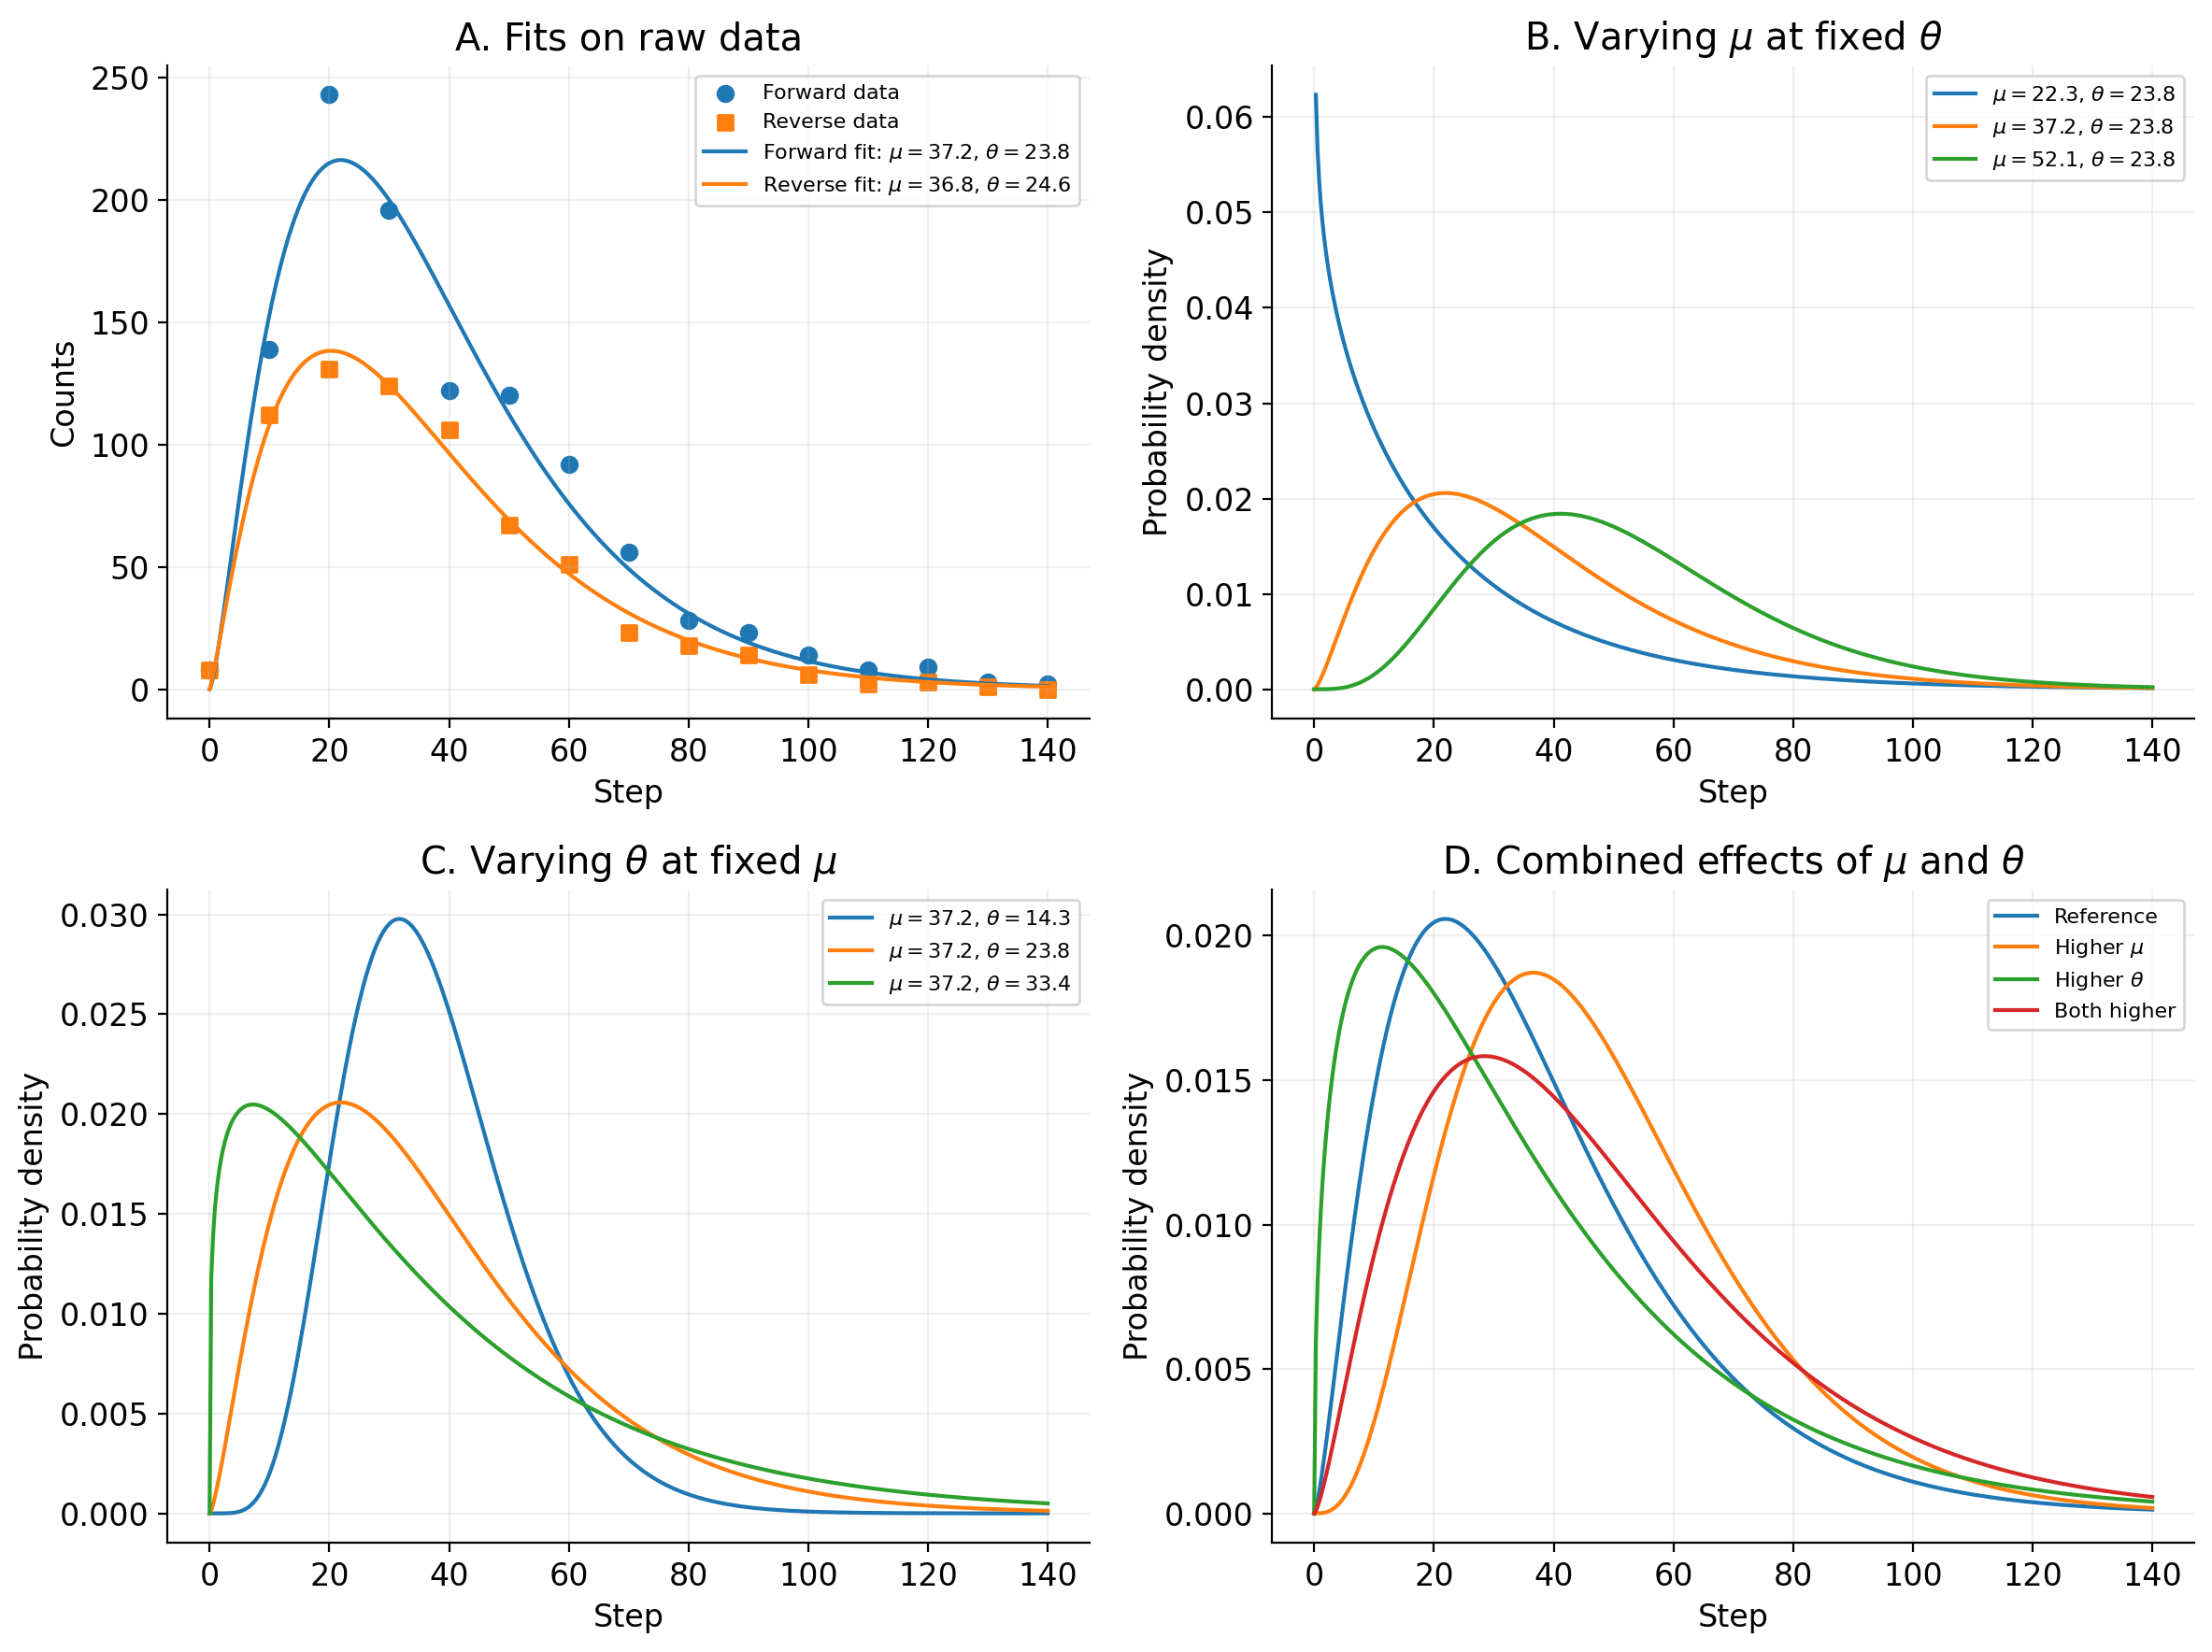

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import gamma


# ============================================================
# 1. DONNÉES BRUTES
# ============================================================

step_array = np.linspace(0, 140, 15)

frwd_array = np.array(
    [8, 139, 243, 196, 122, 120, 92, 56, 28, 23, 14, 8, 9, 3, 2],
    dtype=float
)

rvrs_array = np.array(
    [8, 112, 131, 124, 106, 67, 51, 23, 18, 14, 6, 2, 3, 1, 0],
    dtype=float
)


# ============================================================
# 2. LOI GAMMA PARAMÉTRÉE PAR MU ET THETA
# ============================================================

def gamma_pdf(x, mu, theta):
    """Densité Gamma paramétrée par sa moyenne mu et son écart-type theta."""
    k = (mu / theta) ** 2
    beta = theta**2 / mu

    return gamma.pdf(x, a=k, scale=beta)


def gamma_model(x, amplitude, mu, theta):
    """
    Modèle ajusté aux effectifs bruts.
    L'amplitude absorbe l'échelle des effectifs.
    """
    return amplitude * gamma_pdf(x, mu, theta)


# ============================================================
# 3. FIT SUR LES EFFECTIFS BRUTS
# ============================================================

def fit_gamma(x, y):
    # Estimations initiales à partir des moments des données brutes
    mu0 = np.sum(x * y) / np.sum(y)
    theta0 = np.sqrt(np.sum(y * (x - mu0)**2) / np.sum(y))

    # L'amplitude est ajustée indépendamment de mu et theta
    p0 = [np.sum(y) * (x[1] - x[0]), mu0, theta0]

    params, covariance = curve_fit(
        gamma_model,
        x,
        y,
        p0=p0,
        bounds=(
            [0, 1e-6, 1e-6],
            [np.inf, np.inf, np.inf]
        ),
        maxfev=20_000
    )

    amplitude, mu, theta = params

    return {
        "amplitude": amplitude,
        "mu": mu,
        "theta": theta,
        "covariance": covariance
    }


fit_frwd = fit_gamma(step_array, frwd_array)
fit_rvrs = fit_gamma(step_array, rvrs_array)


# Affichage des paramètres
for name, fit in [("Forward", fit_frwd), ("Reverse", fit_rvrs)]:
    print(
        f"{name:7s} | "
        f"mu = {fit['mu']:.2f} | "
        f"theta = {fit['theta']:.2f}"
    )


# ============================================================
# 4. FIGURE 2x2 : DONNÉES ET VARIATIONS DE MU / THETA
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=200)

x_plot = np.linspace(0, 140, 500)


# ------------------------------------------------------------
# A. Données brutes + fits
# ------------------------------------------------------------

ax = axes[0, 0]

ax.scatter(step_array, frwd_array, label="Forward data", marker="o")
ax.scatter(step_array, rvrs_array, label="Reverse data", marker="s")

ax.plot(
    x_plot,
    gamma_model(
        x_plot,
        fit_frwd["amplitude"],
        fit_frwd["mu"],
        fit_frwd["theta"]
    ),
    label=(
        f"Forward fit: "
        f"$\\mu={fit_frwd['mu']:.1f}$, "
        f"$\\theta={fit_frwd['theta']:.1f}$"
    )
)

ax.plot(
    x_plot,
    gamma_model(
        x_plot,
        fit_rvrs["amplitude"],
        fit_rvrs["mu"],
        fit_rvrs["theta"]
    ),
    label=(
        f"Reverse fit: "
        f"$\\mu={fit_rvrs['mu']:.1f}$, "
        f"$\\theta={fit_rvrs['theta']:.1f}$"
    )
)

ax.set_title("A. Fits on raw data")
ax.set_xlabel("Step")
ax.set_ylabel("Counts")
ax.legend(fontsize=8)


# ------------------------------------------------------------
# B. Variation de mu à theta constant
# ------------------------------------------------------------

ax = axes[0, 1]

mu_ref = fit_frwd["mu"]
theta_ref = fit_frwd["theta"]

mu_values = [0.6 * mu_ref, mu_ref, 1.4 * mu_ref]

for mu in mu_values:
    ax.plot(
        x_plot,
        gamma_pdf(x_plot, mu, theta_ref),
        label=fr"$\mu={mu:.1f}$, $\theta={theta_ref:.1f}$"
    )

ax.set_title(r"B. Varying $\mu$ at fixed $\theta$")
ax.set_xlabel("Step")
ax.set_ylabel("Probability density")
ax.legend(fontsize=8)


# ------------------------------------------------------------
# C. Variation de theta à mu constant
# ------------------------------------------------------------

ax = axes[1, 0]

theta_values = [0.6 * theta_ref, theta_ref, 1.4 * theta_ref]

for theta in theta_values:
    ax.plot(
        x_plot,
        gamma_pdf(x_plot, mu_ref, theta),
        label=fr"$\mu={mu_ref:.1f}$, $\theta={theta:.1f}$"
    )

ax.set_title(r"C. Varying $\theta$ at fixed $\mu$")
ax.set_xlabel("Step")
ax.set_ylabel("Probability density")
ax.legend(fontsize=8)


# ------------------------------------------------------------
# D. Variation simultanée de mu et theta
# ------------------------------------------------------------

ax = axes[1, 1]

parameter_sets = [
    (mu_ref, theta_ref, "Reference"),
    (1.3 * mu_ref, theta_ref, r"Higher $\mu$"),
    (mu_ref, 1.3 * theta_ref, r"Higher $\theta$"),
    (1.3 * mu_ref, 1.3 * theta_ref, "Both higher"),
]

for mu, theta, label in parameter_sets:
    ax.plot(
        x_plot,
        gamma_pdf(x_plot, mu, theta),
        label=label
    )

ax.set_title(r"D. Combined effects of $\mu$ and $\theta$")
ax.set_xlabel("Step")
ax.set_ylabel("Probability density")
ax.legend(fontsize=8)


# ------------------------------------------------------------
# FINALISATION
# ------------------------------------------------------------

for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Forward: mu = 37.20, theta = 23.85


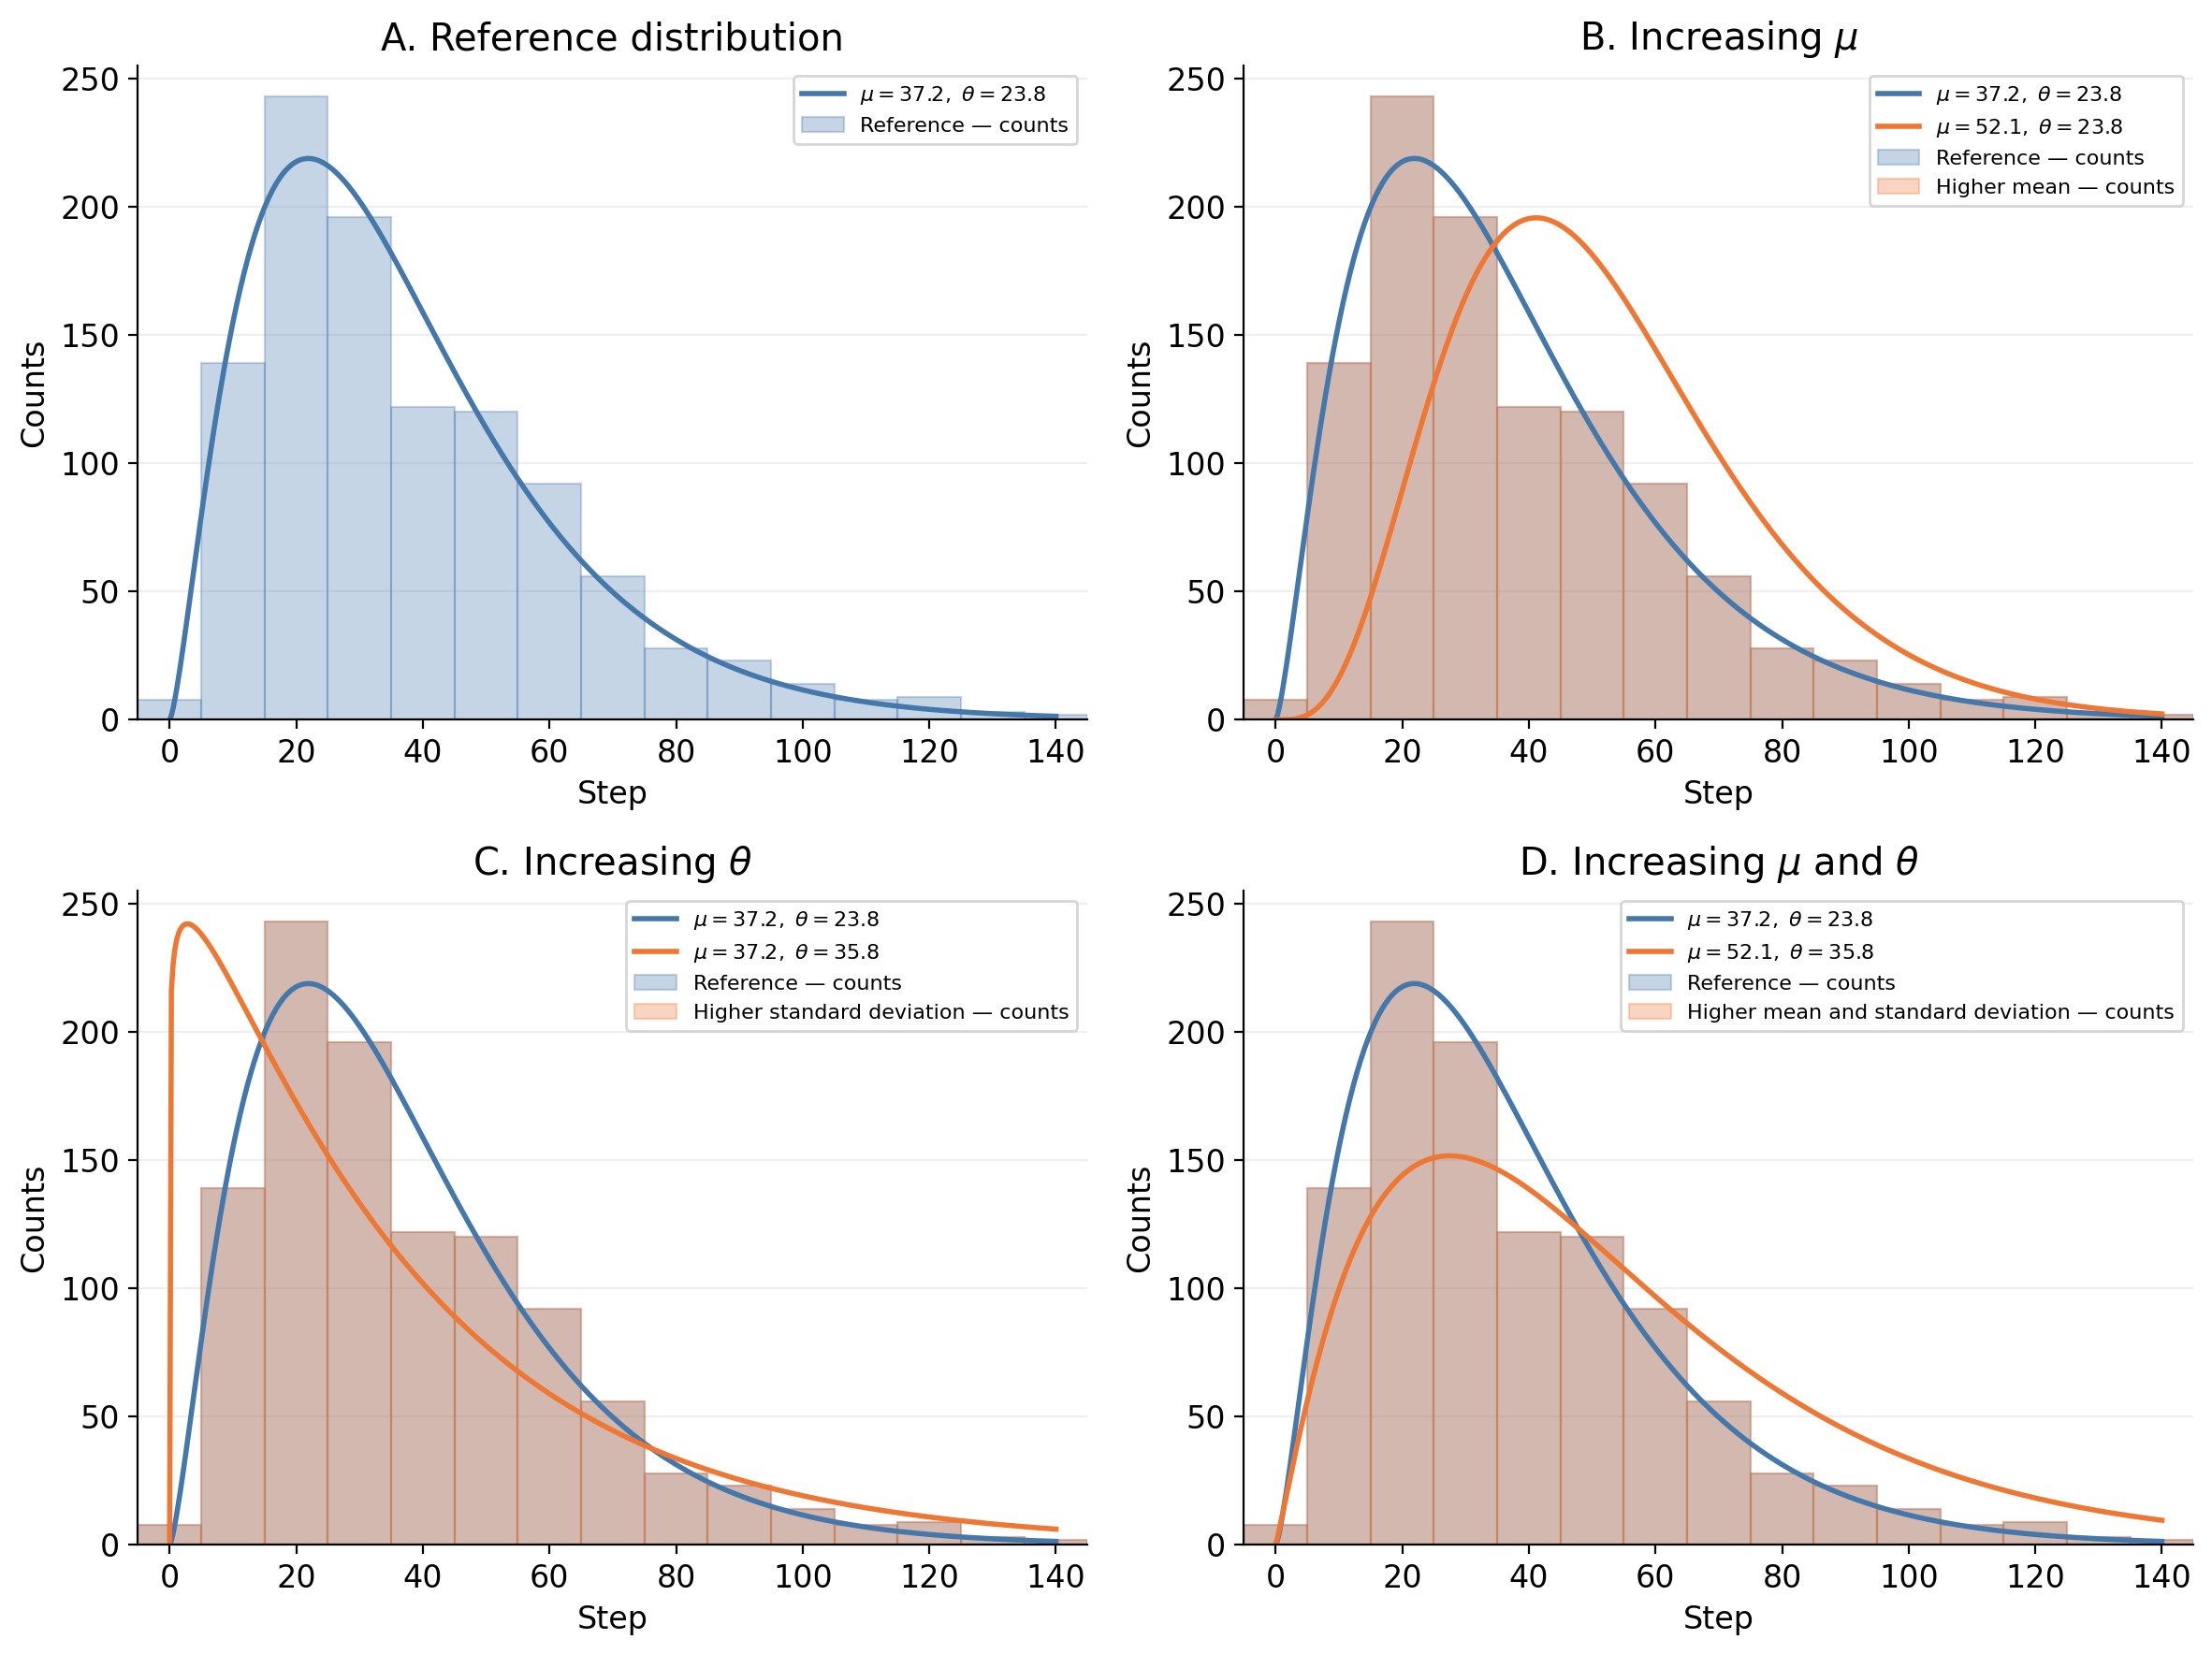

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import gamma


# ============================================================
# 1. DONNÉES BRUTES
# ============================================================

step_array = np.linspace(0, 140, 15)

frwd_array = np.array(
    [8, 139, 243, 196, 122, 120, 92, 56, 28, 23, 14, 8, 9, 3, 2],
    dtype=float
)


# ============================================================
# 2. MODÈLE GAMMA : MU = MOYENNE, THETA = ÉCART-TYPE
# ============================================================

def gamma_pdf(x, mu, theta):
    k = (mu / theta) ** 2
    beta = theta**2 / mu
    return gamma.pdf(x, a=k, scale=beta)


def gamma_model(x, amplitude, mu, theta):
    return amplitude * gamma_pdf(x, mu, theta)


def fit_gamma(x, counts):
    mu0 = np.sum(x * counts) / np.sum(counts)
    theta0 = np.sqrt(np.sum(counts * (x - mu0)**2) / np.sum(counts))

    p0 = [np.sum(counts) * (x[1] - x[0]), mu0, theta0]

    params, _ = curve_fit(
        gamma_model,
        x,
        counts,
        p0=p0,
        bounds=([0, 1e-6, 1e-6], [np.inf, np.inf, np.inf]),
        maxfev=20_000
    )

    return params


amplitude_ref, mu_ref, theta_ref = fit_gamma(step_array, frwd_array)

print(f"Forward: mu = {mu_ref:.2f}, theta = {theta_ref:.2f}")


# ============================================================
# 3. FIGURE 2x2
# ============================================================

BLUE = "#4477AA"
ORANGE = "#EE7733"
GREEN = "#228833"
PURPLE = "#AA3377"

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=200)

x_plot = np.linspace(0, 140, 500)

bin_width = step_array[1] - step_array[0]

# Approximation des limites des bins pour l'affichage
bin_edges = np.linspace(
    step_array[0] - bin_width / 2,
    step_array[-1] + bin_width / 2,
    len(step_array) + 1
)


def plot_distribution(ax, mu, theta, color, label, counts=frwd_array):
    """
    Affiche les counts dans les bins et la loi Gamma ajustée
    à la même échelle verticale.
    """
    ax.bar(
        bin_edges[:-1],
        counts,
        width=bin_width,
        align="edge",
        color=color,
        alpha=0.30,
        edgecolor=color,
        linewidth=0.8,
        label=f"{label} — counts"
    )

    amplitude = np.sum(counts) * bin_width

    ax.plot(
        x_plot,
        amplitude * gamma_pdf(x_plot, mu, theta),
        color=color,
        linewidth=2,
        label=fr"$\mu={mu:.1f},\ \theta={theta:.1f}$"
    )


# ------------------------------------------------------------
# A. Données originales et fit
# ------------------------------------------------------------

ax = axes[0, 0]

plot_distribution(
    ax, mu_ref, theta_ref, BLUE,
    "Reference"
)

ax.set_title("A. Reference distribution")


# ------------------------------------------------------------
# B. Variation de mu
# ------------------------------------------------------------

ax = axes[0, 1]

plot_distribution(
    ax, mu_ref, theta_ref, BLUE,
    "Reference"
)

plot_distribution(
    ax, 1.4 * mu_ref, theta_ref, ORANGE,
    "Higher mean"
)

ax.set_title(r"B. Increasing $\mu$")


# ------------------------------------------------------------
# C. Variation de theta
# ------------------------------------------------------------

ax = axes[1, 0]

plot_distribution(
    ax, mu_ref, theta_ref, BLUE,
    "Reference"
)

plot_distribution(
    ax, mu_ref, 1.5 * theta_ref, ORANGE,
    "Higher standard deviation"
)

ax.set_title(r"C. Increasing $\theta$")


# ------------------------------------------------------------
# D. Variations combinées
# ------------------------------------------------------------

ax = axes[1, 1]

plot_distribution(
    ax, mu_ref, theta_ref, BLUE,
    "Reference"
)

plot_distribution(
    ax, 1.4 * mu_ref, 1.5 * theta_ref, ORANGE,
    "Higher mean and standard deviation"
)

ax.set_title(r"D. Increasing $\mu$ and $\theta$")


# ============================================================
# 4. FINITIONS
# ============================================================

for ax in axes.flat:
    ax.set_xlabel("Step")
    ax.set_ylabel("Counts")
    ax.set_xlim(-bin_width / 2, 140 + bin_width / 2)
    ax.set_ylim(bottom=0)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()